In [74]:
import xarray as xr
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pvlib

In [ ]:
#open the datafile
ds = xr.open_dataset(r"C:\Users\Aromal\Documents\solar_project\data\OLUOL.cleaned.nc")
ds

<xarray.Dataset> Size: 55MB
Dimensions:       (time: 525600)
Coordinates:
  * time          (time) datetime64[ns] 4MB 2022-04-01T00:01:00 ... 2023-04-01
    latitude      float64 8B ...
    longitude     float64 8B ...
    elevation     int64 8B ...
Data variables: (12/14)
    GTI_30_180    (time) float64 4MB ...
    cDNI          (time) float64 4MB ...
    RH            (time) float64 4MB ...
    cGHI          (time) float64 4MB ...
    turbidity     (time) float64 4MB ...
    SAZ           (time) float64 4MB ...
    ...            ...
    T             (time) float64 4MB ...
    DHI           (time) float64 4MB ...
    cDHI          (time) float64 4MB ...
    SZA           (time) float64 4MB ...
    station_name  <U5 20B ...
    crs           int64 8B ...
Attributes: (12/36)
    grid_mapping_name:            latitude_longitude
    longitude_of_prime_meridian:  0.0
    semi_major_axis:              6378137.0
    inverse_flattening:           298.257223563
    epsg_code:                    EPSG:4326
    title:                        Timeseries of solar irradiance and meteorol...
    ...                           ...
    height:                       15
    license:                      https://cdla.dev/sharing-1-0/
    qc_level:                     quality controlled + cleaned data
    surface_type:                 roof,pebbles
    topography_type:              flat
    rural_urban:                  suburban

In [ ]:
#checking the attributes of needed variables
for var in ["GHI", "DNI", "DHI", "cGHI", "cDNI", "cDHI", "turbidity", "SZA", "SAZ"]:
    print(f"{var}")
    print(ds[var].attrs)
    print()

GHI
{'DIMENSION_LABELS': 'time', 'orig_name': 'reference pyranometer, corrected with RSI formula', 'interval_type': 'left_closed/right_open/label_right', 'meas_type': 'avg', 'sensor_brand': 'LI-COR', 'sensor_model': 'LI-200', 'sensor_type': 'photodiode', 'long_name': 'Global Horizontal Irradiance', 'standard_name': 'surface_downwelling_shortwave_flux_in_air', 'abbreviation': 'GHI', 'units': 'W m-2', 'valid_min_': np.float64(0.0), 'valid_max_': np.int64(3000), 'grid_mapping': 'crs'}

DNI
{'DIMENSION_LABELS': 'time', 'orig_name': 'dni (RSI), corrected with RSI formula', 'interval_type': 'left_closed/right_open/label_right', 'meas_type': 'avg', 'sensor_brand': 'LI-COR', 'sensor_model': 'LI-200', 'sensor_type': 'photodiode', 'long_name': 'Beam (or Direct) Normal Irradiance', 'standard_name': 'direct_downwelling_shortwave_flux_in_air', 'abbreviation': 'DNI', 'units': 'W m-2', 'valid_min_': np.float64(0.0), 'valid_max_': np.int64(3000), 'grid_mapping': 'crs'}

DHI
{'DIMENSION_LABELS': 'time'

In [ ]:
#checking the corrdinates
latitude = float(ds["latitude"].values)
longitude = float(ds["longitude"].values)
print(latitude,longitude)

53.15348 8.16192


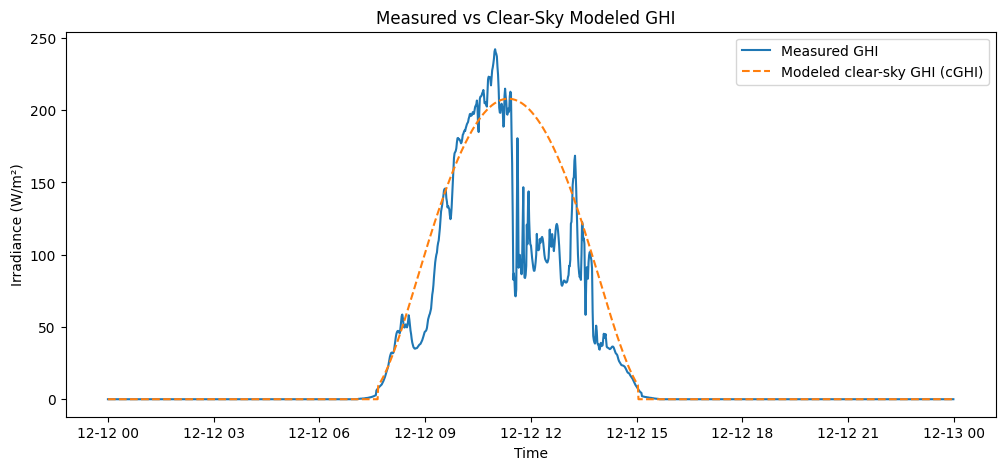

In [43]:
#looking through different days
day = ds.sel(time="2022-12-12")

plt.figure(figsize=(12,5))
plt.plot(day.time, day["GHI"], label="Measured GHI")
plt.plot(day.time, day["cGHI"], label="Modeled clear-sky GHI (cGHI)", linestyle="--")
plt.xlabel("Time")
plt.ylabel("Irradiance (W/m²)")
plt.title("Measured vs Clear-Sky Modeled GHI  ")
plt.legend()
plt.show()

In [ ]:
#total timestamps available
ds.sizes["time"]

525600

In [ ]:
#filtering out the clearsky moments 
daytime_mask = (ds["SZA"] < 75).values

# Reno-Hansen detection 
ghi_series = ds["GHI"].to_series()
cghi_series = ds["cGHI"].to_series()

rh_mask_raw = pvlib.clearsky.detect_clearsky(
    measured=ghi_series,
    clearsky=cghi_series,
    times=ghi_series.index
)

# Restrict to daytime 
clear_sky_mask = rh_mask_raw.values & daytime_mask
ds["clear_sky_mask"] = ("time", clear_sky_mask)

n_daytime = daytime_mask.sum()
n_clear = clear_sky_mask.sum()
print(f"Daytime timestamps (SZA<75): {n_daytime}")
print(f"Reno-Hansen clear-sky timestamps: {n_clear}  ({n_clear/n_daytime:.2%})")


Daytime timestamps (SZA<75): 169898
Reno-Hansen clear-sky timestamps: 22875  (13.46%)


In [ ]:
#verifying the elevation of station above sea level
print("elevation:", ds.attrs["elevation"])
print("height:", ds.attrs["height"])

elevation: 21
height: 15


In [ ]:
#absolute airmass and pressure
altitude = ds.attrs["elevation"]  

apparent_zenith = ds["SZA"].to_series()

airmass_relative = pvlib.atmosphere.get_relative_airmass(apparent_zenith, model="kastenyoung1989")
pressure = pvlib.atmosphere.alt2pres(altitude)
airmass_absolute = pvlib.atmosphere.get_absolute_airmass(airmass_relative, pressure)

ds["airmass"] = ("time", airmass_absolute.values)

final_mask = ds["clear_sky_mask"]
ds["final_mask"] = final_mask

print(altitude, pressure)
print(ds['clear_sky_mask'].sum().values, final_mask.sum().values)

21 101072.98120568051
22875 22875


In [ ]:
#Calculate Turbidity using the Ineichen Perez Airmass independent formula
doy = ds["time"].dt.dayofyear.values
I0 = 1367 * (1 + 0.033 * np.cos(2 * np.pi * doy / 365))

fh1 = np.exp(-altitude / 8000.0)
b = 0.664 + 0.163 / fh1

DNI = ds["DNI"].values
AM = ds["airmass"].values
mask = ds["final_mask"].values

TL_raw = np.full(len(DNI), np.nan)
valid = mask & (DNI > 0)
TL_raw[valid] = 1 + np.log(b * I0[valid] / DNI[valid]) / (0.09 * AM[valid])

TL_derived = TL_raw.copy()
low_tl = valid & (TL_raw < 2)
TL_derived[low_tl] = TL_raw[low_tl] - 0.25 * np.sqrt(2 - TL_raw[low_tl])

ds["TL_derived"] = ("time", TL_derived)

print(valid.sum())
print(f"Points receiving low-T_L correction: {low_tl.sum()}")
print(np.nanmean(TL_derived), np.nanmedian(TL_derived))
print(np.nanmin(TL_derived), np.nanmax(TL_derived))

22875
Points receiving low-T_L correction: 49
2.936505671222843 2.8457108894987653
1.5695070082815716 6.927559679818155


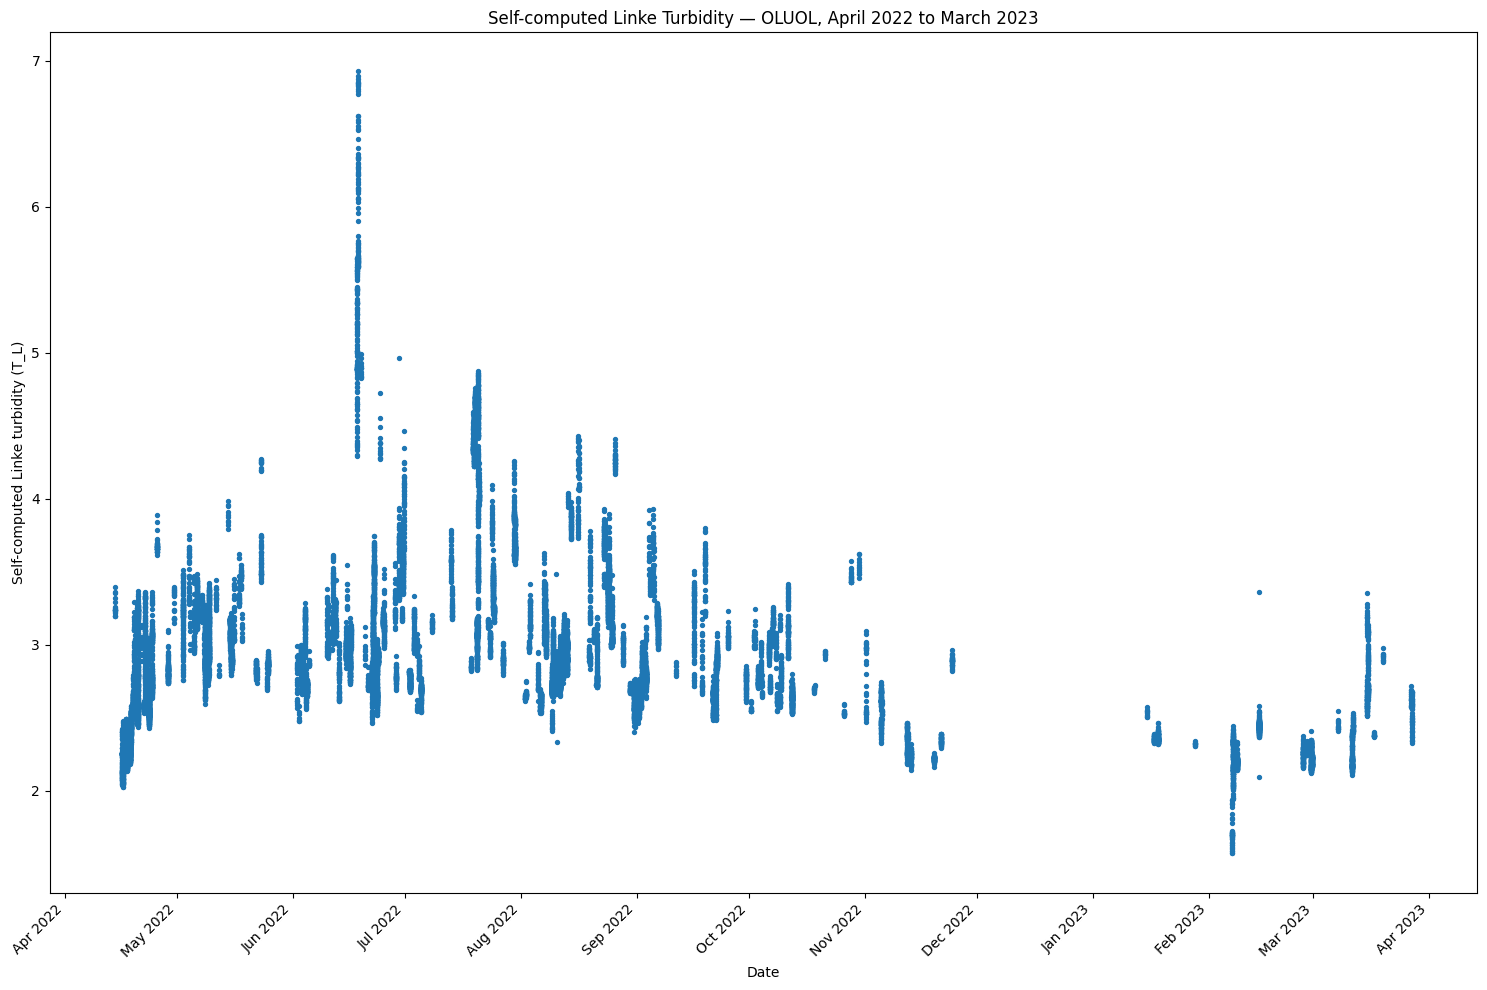

In [ ]:
#Plotting the given Turbidity values
import matplotlib.dates as mdates

valid = ds["final_mask"].values

fig, ax = plt.subplots(figsize=(15,10))
ax.scatter(ds["time"].values[valid], ds["TL_derived"].values[valid], s=8, color="tab:blue")

ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
plt.setp(ax.xaxis.get_majorticklabels(), rotation=45, ha="right")

ax.set_xlabel("Date")
ax.set_ylabel("Self-computed Linke turbidity (T_L)")
ax.set_title("Self-computed Linke Turbidity — OLUOL, April 2022 to March 2023")
plt.tight_layout()
plt.show()


In [ ]:
#Checking through the Turbidity statistics
df = ds[["TL_derived"]].to_dataframe().dropna()
print(df["TL_derived"].describe())
print(df["TL_derived"].idxmax(), df["TL_derived"].max())

#Turbidity count size per month
monthly_stats = df.groupby(df.index.to_period("M"))["TL_derived"].describe()
print(monthly_stats)


count    22875.000000
mean         2.936506
std          0.555636
min          1.569507
25%          2.637986
50%          2.845711
75%          3.118788
max          6.927560
Name: TL_derived, dtype: float64
2022-06-18 11:03:00 6.927559679818155
          count      mean       std       min       25%       50%       75%  \
time                                                                          
2022-04  3845.0  2.591479  0.323762  2.022802  2.306272  2.547354  2.785429   
2022-05  2323.0  3.055877  0.234444  2.590581  2.878362  2.998340  3.187270   
2022-06  3673.0  3.191020  0.702000  2.466456  2.802613  2.954583  3.286281   
2022-07  2481.0  3.602762  0.677123  2.539204  3.013722  3.484528  4.353387   
2022-08  4980.0  2.968179  0.332079  2.336420  2.750652  2.880197  3.070951   
2022-09  2100.0  2.855065  0.273990  2.465882  2.662114  2.768348  2.976010   
2022-10   952.0  2.857420  0.240934  2.513120  2.654534  2.781221  3.027513   
2022-11   512.0  2.453693  0.222104  2.143

In [ ]:
#checking the peak turbidity 
window = ds["TL_derived"].sel(time=slice("2022-06-18 08:00", "2022-06-18 12:00")).to_series().dropna()
print(window)
print(f"\nNumber of points: {len(window)}")

time
2022-06-18 08:00:00    5.693551
2022-06-18 08:01:00    5.700649
2022-06-18 08:02:00    5.738328
2022-06-18 08:03:00    5.750465
2022-06-18 08:04:00    5.715085
                         ...   
2022-06-18 10:59:00    6.774486
2022-06-18 11:00:00    6.790925
2022-06-18 11:01:00    6.805718
2022-06-18 11:02:00    6.899704
2022-06-18 11:03:00    6.927560
Name: TL_derived, Length: 62, dtype: float64

Number of points: 62


In [94]:
window = ds["TL_derived"].sel(time=slice("2022-06-18 07:00", "2022-06-18 12:00")).to_series()

half_hourly = window.resample("30min").mean()
print(half_hourly)
half_hourly_clean = half_hourly.dropna()
print(half_hourly_clean)

time
2022-06-18 07:00:00    5.546007
2022-06-18 07:30:00    5.639068
2022-06-18 08:00:00    6.021020
2022-06-18 08:30:00    6.414911
2022-06-18 09:00:00         NaN
2022-06-18 09:30:00         NaN
2022-06-18 10:00:00         NaN
2022-06-18 10:30:00    6.838041
2022-06-18 11:00:00    6.855977
2022-06-18 11:30:00         NaN
2022-06-18 12:00:00         NaN
Freq: 30min, Name: TL_derived, dtype: float64
time
2022-06-18 07:00:00    5.546007
2022-06-18 07:30:00    5.639068
2022-06-18 08:00:00    6.021020
2022-06-18 08:30:00    6.414911
2022-06-18 10:30:00    6.838041
2022-06-18 11:00:00    6.855977
Name: TL_derived, dtype: float64


In [ ]:
#getting the Climatological turbidity value
climatology = pvlib.clearsky.lookup_linke_turbidity(
    time=ds["time"].to_index(),
    latitude=float(ds["latitude"].values),
    longitude=float(ds["longitude"].values)
)

ds["TL_climatology"] = ("time", climatology.values)

print(ds["TL_climatology"].to_series().resample("MS").mean())

time
2022-04-01    3.468852
2022-05-01    3.565177
2022-06-01    3.766393
2022-07-01    4.020964
2022-08-01    4.053533
2022-09-01    3.795082
2022-10-01    3.474775
2022-11-01    3.088525
2022-12-01    2.948579
2023-01-01    2.868705
2023-02-01    2.970763
2023-03-01    3.419420
2023-04-01    3.472951
Freq: MS, Name: TL_climatology, dtype: float64


In [ ]:
#comparing the climatological turbidity with median of calculated turbidity
derived = ds["TL_derived"].to_series().dropna()
climatology_series = ds["TL_climatology"].to_series()

comparison = pd.DataFrame({
    "TL_derived_median": derived.groupby(derived.index.to_period("M")).median(),
    "TL_derived_count": derived.groupby(derived.index.to_period("M")).count(),
    "TL_climatology_mean": climatology_series.groupby(climatology_series.index.to_period("M")).mean()
})

comparison["difference"] = comparison["TL_climatology_mean"] - comparison["TL_derived_median"]
comparison["pct_difference"] = 100 * comparison["difference"] / comparison["TL_derived_median"]

print(comparison)

         TL_derived_median  TL_derived_count  TL_climatology_mean  difference  \
time                                                                            
2022-04           2.592622            2549.0             3.468852    0.876230   
2022-05           3.036842            1400.0             3.565177    0.528335   
2022-06           2.973637            2236.0             3.766393    0.792756   
2022-07           3.163422            1430.0             4.020964    0.857542   
2022-08           2.874571            3211.0             4.053533    1.178963   
2022-09           2.780682            1824.0             3.795082    1.014400   
2022-10           2.781221             952.0             3.474775    0.693554   
2022-11           2.386171             512.0             3.088525    0.702353   
2022-12                NaN               NaN             2.948579         NaN   
2023-01           2.353801             185.0             2.868705    0.514904   
2023-02           2.242225  

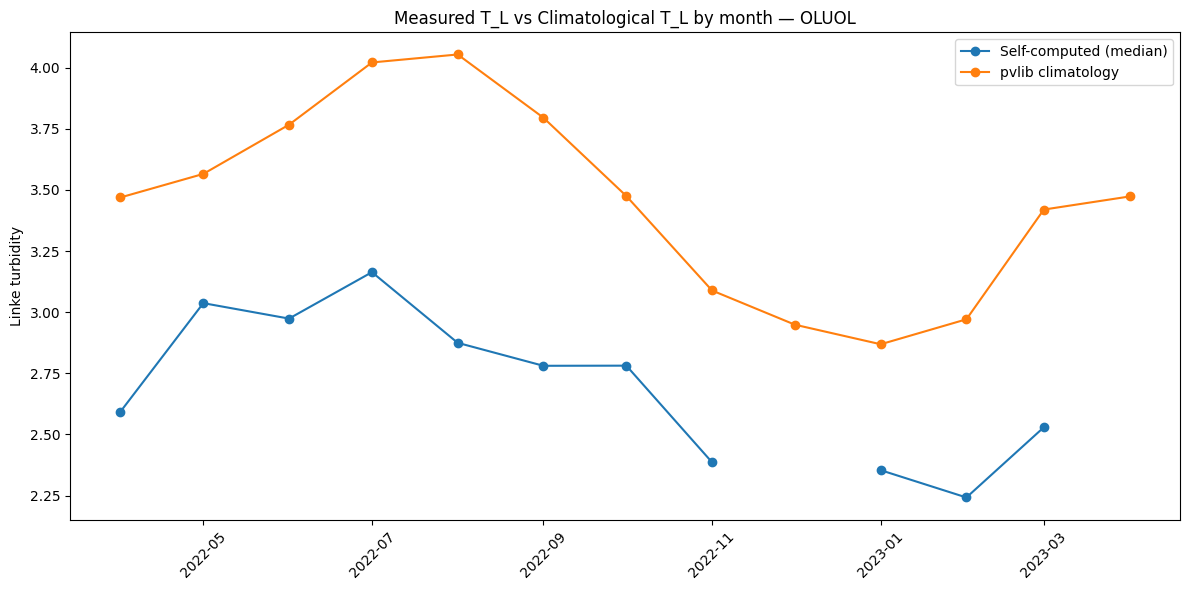

In [ ]:
#plotting both 
if not isinstance(comparison.index, pd.DatetimeIndex):
    comparison.index = comparison.index.to_timestamp()

fig, ax = plt.subplots(figsize=(12,6))
ax.plot(comparison.index, comparison["TL_derived_median"], marker="o", label="Self-computed (median)")
ax.plot(comparison.index, comparison["TL_climatology_mean"], marker="o", label="pvlib climatology")
ax.set_ylabel("Linke turbidity")
ax.set_title("Measured T_L vs Climatological T_L by month — OLUOL")
ax.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [57]:
lowest_month = comparison["TL_climatology_mean"].idxmin()
highest_month = comparison["TL_climatology_mean"].idxmax()

print("Lowest climatological turbidity month:", lowest_month, comparison.loc[lowest_month, "TL_climatology_mean"])
print("Highest climatological turbidity month:", highest_month, comparison.loc[highest_month, "TL_climatology_mean"])

Lowest climatological turbidity month: 2023-01-01 00:00:00 2.868704915430607
Highest climatological turbidity month: 2022-08-01 00:00:00 4.053533290117875


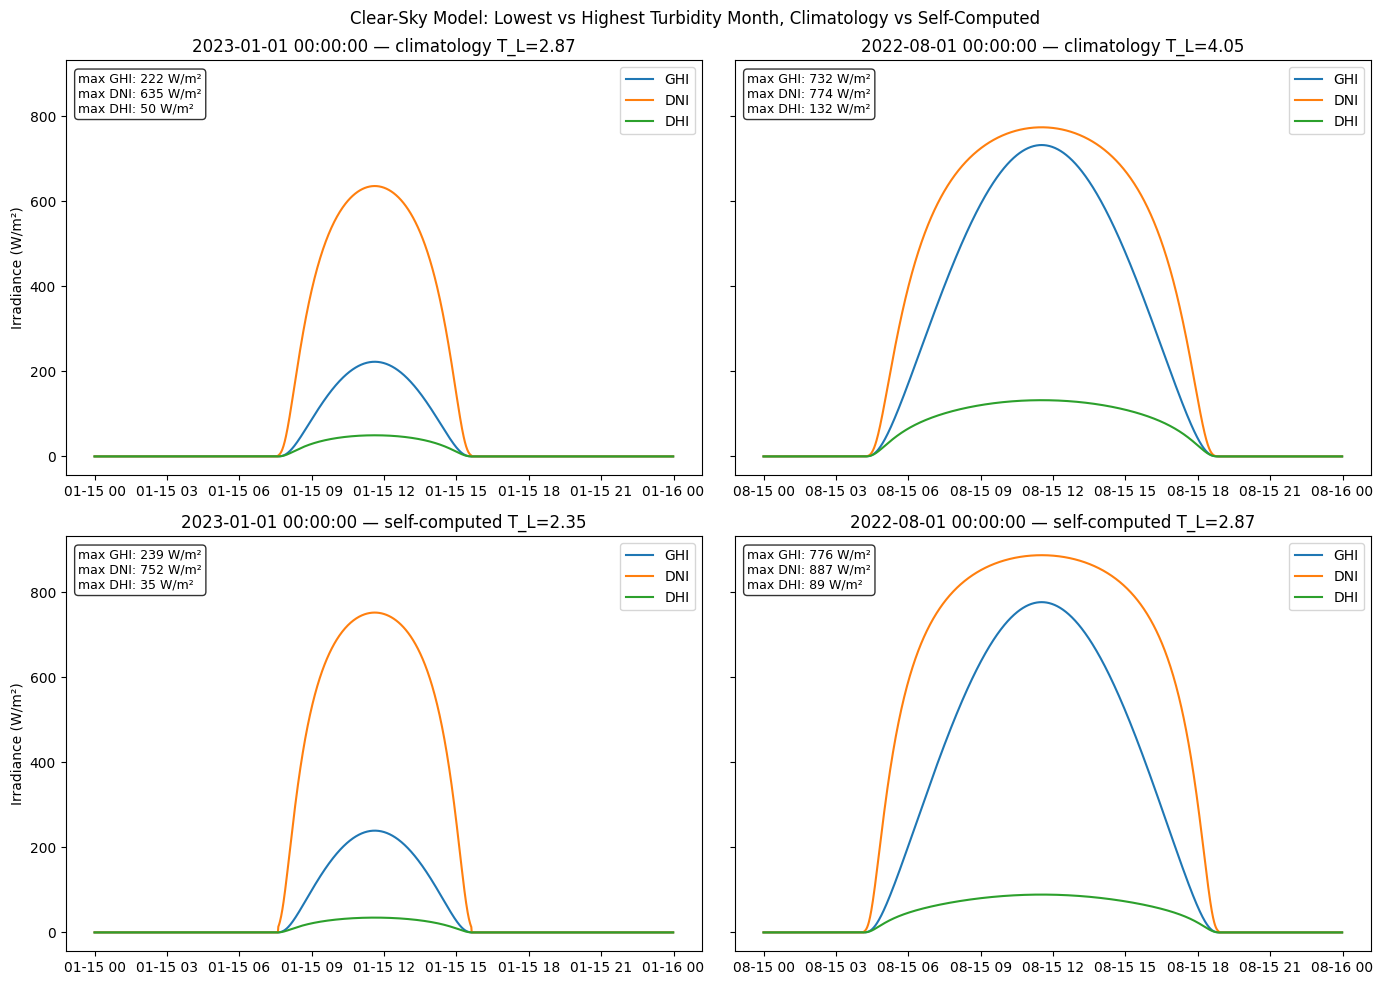

In [ ]:
#effect on solar irradiance
from pvlib import solarposition, irradiance, clearsky

def clearsky_for_month(period, day_of_month=15):
    day = pd.Timestamp(period.year, period.month, day_of_month)
    times = pd.date_range(day, day + pd.Timedelta(hours=23, minutes=59), freq="1min", tz="UTC")
    solpos = solarposition.get_solarposition(times, latitude, longitude)
    apparent_zenith = solpos["apparent_zenith"]
    airmass_rel = pvlib.atmosphere.get_relative_airmass(apparent_zenith)
    airmass_abs = pvlib.atmosphere.get_absolute_airmass(airmass_rel, pressure)
    dni_extra = irradiance.get_extra_radiation(times)

    tl_clim = comparison.loc[period, "TL_climatology_mean"]
    tl_meas = comparison.loc[period, "TL_derived_median"]

    cs_clim = clearsky.ineichen(apparent_zenith, airmass_abs, tl_clim, altitude, dni_extra)
    cs_meas = clearsky.ineichen(apparent_zenith, airmass_abs, tl_meas, altitude, dni_extra)
    return times, cs_clim, cs_meas, tl_clim, tl_meas

def annotate_peaks(ax, cs):
    text = (f"max GHI: {cs['ghi'].max():.0f} W/m²\n"
            f"max DNI: {cs['dni'].max():.0f} W/m²\n"
            f"max DHI: {cs['dhi'].max():.0f} W/m²")
    ax.text(0.02, 0.97, text, transform=ax.transAxes,
            fontsize=9, va="top", ha="left",
            bbox=dict(boxstyle="round", facecolor="white", alpha=0.8))

fig, axes = plt.subplots(2, 2, figsize=(14, 10), sharey=True)

for col, period in enumerate([lowest_month, highest_month]):
    times, cs_clim, cs_meas, tl_clim, tl_meas = clearsky_for_month(period)

    axes[0, col].plot(times, cs_clim["ghi"], label="GHI")
    axes[0, col].plot(times, cs_clim["dni"], label="DNI")
    axes[0, col].plot(times, cs_clim["dhi"], label="DHI")
    axes[0, col].set_title(f"{period} — climatology T_L={tl_clim:.2f}")
    annotate_peaks(axes[0, col], cs_clim)

    axes[1, col].plot(times, cs_meas["ghi"], label="GHI")
    axes[1, col].plot(times, cs_meas["dni"], label="DNI")
    axes[1, col].plot(times, cs_meas["dhi"], label="DHI")
    axes[1, col].set_title(f"{period} — self-computed T_L={tl_meas:.2f}")
    annotate_peaks(axes[1, col], cs_meas)

for ax in axes.flat:
    ax.legend(loc="upper right")
axes[0,0].set_ylabel("Irradiance (W/m²)")
axes[1,0].set_ylabel("Irradiance (W/m²)")

fig.suptitle("Clear-Sky Model: Lowest vs Highest Turbidity Month, Climatology vs Self-Computed")
plt.tight_layout()
plt.show()

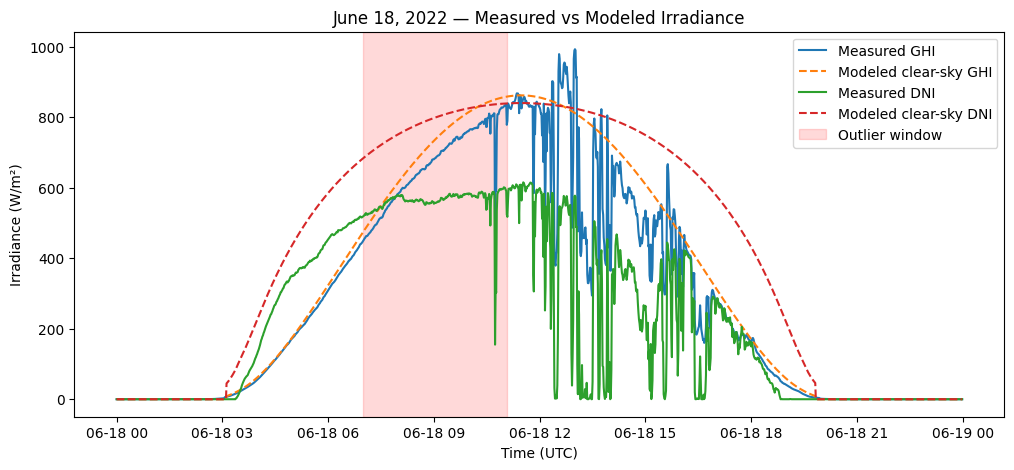

In [ ]:
#June 18 
day = ds.sel(time="2022-06-18")

fig, ax = plt.subplots(figsize=(12,5))
ax.plot(day.time, day["GHI"], label="Measured GHI")
ax.plot(day.time, day["cGHI"], label="Modeled clear-sky GHI", linestyle="--")
ax.plot(day.time, day["DNI"], label="Measured DNI")
ax.plot(day.time, day["cDNI"], label="Modeled clear-sky DNI", linestyle="--")
ax.axvspan(pd.Timestamp("2022-06-18 07:00"), pd.Timestamp("2022-06-18 11:05"),
           color="red", alpha=0.15, label="Outlier window")
ax.set_xlabel("Time (UTC)")
ax.set_ylabel("Irradiance (W/m²)")
ax.set_title("June 18, 2022 — Measured vs Modeled Irradiance")
ax.legend()
plt.show()

In [97]:
df = ds[["TL_derived"]].to_dataframe().dropna()
peak_time = df["TL_derived"].idxmax()
print("Peak timestamp:", peak_time)

check_times = pd.to_datetime([peak_time])
print(ds["SZA"].sel(time=check_times, method="nearest").values)
print(ds["airmass"].sel(time=check_times, method="nearest").values)

Peak timestamp: 2022-06-18 11:03:00
[30.11202842]
[1.15242236]


In [ ]:
#Getting the AOD from CAMS
import cdsapi

client = cdsapi.Client()
client.retrieve(
    "cams-global-reanalysis-eac4",
    {
        "date": "2022-06-18/2022-06-18",
        "time": ["06:00", "09:00", "12:00", "15:00", "18:00"],
        "variable": "total_aerosol_optical_depth_550nm",
        "area": [54, 7, 52, 9],
        "format": "netcdf",
    },
    "cams_aod_20220618_3hr.nc"
)

print("Download complete.")

2026-07-06 12:27:31,697 INFO Request ID is 45e31d48-95e4-47a4-89d9-33543c40fa2d
2026-07-06 12:27:31,797 INFO status has been updated to accepted
2026-07-06 12:27:45,592 INFO status has been updated to running
2026-07-06 12:27:53,265 INFO status has been updated to successful


6d70725183cc679c628c7618c503a981.nc:   0%|          | 0.00/24.3k [00:00<?, ?B/s]

Download complete.


In [101]:
aod_ds_day = xr.open_dataset("cams_aod_20220618_3hr.nc")

aod_point_day = aod_ds_day["aod550"].sel(
    latitude=53.15348, longitude=8.16192, method="nearest"
)

for t, v in zip(aod_point_day["valid_time"].values, aod_point_day.values):
    print(pd.Timestamp(t), "->", round(float(v), 4))

2022-06-18 06:00:00 -> 0.2549
2022-06-18 09:00:00 -> 0.2639
2022-06-18 12:00:00 -> 0.4954
2022-06-18 15:00:00 -> 0.5952
2022-06-18 18:00:00 -> 0.5673


In [103]:
client.retrieve(
    "cams-global-reanalysis-eac4",
    {
        "date": "2022-06-18/2022-06-18",
        "time": ["06:00", "09:00", "12:00", "15:00", "18:00"],
        "variable": [
            "dust_aerosol_optical_depth_550nm",
            "organic_matter_aerosol_optical_depth_550nm",
            "black_carbon_aerosol_optical_depth_550nm",
            "sulphate_aerosol_optical_depth_550nm",
            "sea_salt_aerosol_optical_depth_550nm",
            "total_column_water_vapour"
        ],
        "area": [54, 7, 52, 9],
        "format": "netcdf",
    },
    "cams_species_20220618_v3.nc"
)

print("Download complete.")

2026-07-06 12:29:39,913 INFO Request ID is 39c1b055-b198-4758-920b-0b88a620a1b6
2026-07-06 12:29:40,110 INFO status has been updated to accepted
2026-07-06 12:30:01,445 INFO status has been updated to running
2026-07-06 12:30:12,985 INFO status has been updated to successful


2d0c9a5a654bc82e65e22792c0b502aa.nc:   0%|          | 0.00/69.5k [00:00<?, ?B/s]

Download complete.


In [104]:
species_ds = xr.open_dataset("cams_species_20220618.nc")
print(list(species_ds.data_vars))

['duaod550', 'omaod550', 'bcaod550', 'suaod550', 'ssaod550', 'tcwv']


In [ ]:
#Species wise data from CAM
species_ds = xr.open_dataset("cams_species_20220618_v3.nc")

species_point = species_ds.sel(latitude=53.15348, longitude=8.16192, method="nearest")

species_df = pd.DataFrame({
    "dust": species_point["duaod550"].values,
    "organic_matter": species_point["omaod550"].values,
    "black_carbon": species_point["bcaod550"].values,
    "sulphate": species_point["suaod550"].values,
    "sea_salt": species_point["ssaod550"].values,
    "water_vapour_kg_m2": species_point["tcwv"].values,
}, index=species_point["valid_time"].values)

print(species_df)

                         dust  organic_matter  black_carbon  sulphate  \
2022-06-18 06:00:00  0.135978        0.060374      0.005649  0.043478   
2022-06-18 09:00:00  0.130571        0.065881      0.006140  0.050099   
2022-06-18 12:00:00  0.249699        0.119646      0.011660  0.096669   
2022-06-18 15:00:00  0.298278        0.138510      0.012382  0.124798   
2022-06-18 18:00:00  0.314375        0.119059      0.010092  0.107474   

                     sea_salt  water_vapour_kg_m2  
2022-06-18 06:00:00  0.009428           30.312927  
2022-06-18 09:00:00  0.011177           33.693283  
2022-06-18 12:00:00  0.017714           35.309952  
2022-06-18 15:00:00  0.021274           36.497910  
2022-06-18 18:00:00  0.016260           36.266052  
